# Real-Time Multimodal Emotion Recognition

Portfolio edition: local machine paths have been replaced with repository-relative paths. Datasets and trained weights are intentionally excluded; see the repository README for setup and provenance.


In [ ]:
import os
import cv2
import time
import yaml
import math
import random
import shutil
import numpy as np
from pathlib import Path
from collections import Counter

FER_ROOT = Path(r"data/fer2013")
assert FER_ROOT.exists(), f"FER_ROOT not found: {FER_ROOT}"
print("✅ FER_ROOT:", FER_ROOT)


✅ FER_ROOT: data/fer2013


In [ ]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(p: Path):
    if not p.exists():
        return 0
    return sum(1 for x in p.rglob("*") if x.suffix.lower() in IMG_EXTS)

def list_subdirs(p: Path):
    return [d for d in p.iterdir() if d.is_dir()] if p.exists() else []

def detect_layout(fer_root: Path):
    csv_path = fer_root / "fer2013.csv"
    if csv_path.exists():
        return ("csv", csv_path)

    # common folder layouts
    for a, b in [
        (fer_root / "train", fer_root / "val"),
        (fer_root / "train", fer_root / "test"),
        (fer_root / "images" / "train", fer_root / "images" / "val"),
        (fer_root / "images" / "train", fer_root / "images" / "test"),
    ]:
        if a.exists() and a.is_dir():
            # must contain class folders and images
            class_dirs = [d for d in a.iterdir() if d.is_dir()]
            if len(class_dirs) >= 3:
                img_count = count_images(a)
                if img_count > 0:
                    return ("folders", (a, b if b.exists() else None))

    # fallback: search for any folder named "train" containing images
    train_candidates = [p for p in fer_root.rglob("train") if p.is_dir()]
    for tr in train_candidates:
        if count_images(tr) > 0 and len([d for d in tr.iterdir() if d.is_dir()]) >= 3:
            # try to find sibling val/test
            parent = tr.parent
            val = parent / "val"
            test = parent / "test"
            return ("folders", (tr, val if val.exists() else (test if test.exists() else None)))

    return ("unknown", None)

layout, layout_info = detect_layout(FER_ROOT)
print("FER layout:", layout)

if layout == "csv":
    print("✅ Found CSV:", layout_info)
elif layout == "folders":
    tr, va = layout_info
    print("✅ Found train folder:", tr)
    print("✅ Found val/test folder:", va)
else:
    raise FileNotFoundError(
        "Could not detect FER dataset layout. "
        "Expected fer2013.csv or train/val folders with class subfolders."
    )


FER layout: folders
✅ Found train folder: data/fer2013\train
✅ Found val/test folder: data/fer2013\val


In [ ]:
# Only run if layout == "csv"
from PIL import Image

CSV_PATH = layout_info
OUT_ROOT = FER_ROOT / "fer_yolo_cls"   # where we will create images/train|val
TRAIN_OUT = OUT_ROOT / "train"
VAL_OUT   = OUT_ROOT / "val"

# FER2013 standard labels (0..6)
FER_LABELS = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]

def ensure_dir(p: Path):
    p.mkdir(parents=True, exist_ok=True)

def safe_clean_dir(p: Path):
    if p.exists():
        shutil.rmtree(p)
    p.mkdir(parents=True, exist_ok=True)

safe_clean_dir(OUT_ROOT)
for split_dir in [TRAIN_OUT, VAL_OUT]:
    for name in FER_LABELS:
        ensure_dir(split_dir / name)

# Read CSV manually (fast + robust)
import csv
rows = []
with open(CSV_PATH, "r", newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for r in reader:
        rows.append(r)

print("CSV rows:", len(rows))
# Expect columns: emotion, pixels, Usage
# Usage values usually: Training, PublicTest, PrivateTest

def row_to_img(pixels_str: str):
    arr = np.fromstring(pixels_str, sep=" ", dtype=np.uint8)
    if arr.size != 48 * 48:
        return None
    img = arr.reshape(48, 48)
    return img

counts = Counter()
bad = 0

for idx, r in enumerate(rows):
    try:
        emo = int(r["emotion"])
        usage = r.get("Usage", "").strip()
        px = r["pixels"]
    except Exception:
        bad += 1
        continue

    if emo < 0 or emo >= len(FER_LABELS):
        bad += 1
        continue

    img48 = row_to_img(px)
    if img48 is None:
        bad += 1
        continue

    # split mapping
    if usage.lower() == "training":
        split_dir = TRAIN_OUT
    else:
        # PublicTest + PrivateTest -> val
        split_dir = VAL_OUT

    cls_name = FER_LABELS[emo]
    out_path = split_dir / cls_name / f"{idx:07d}.jpg"

    Image.fromarray(img48).convert("RGB").save(out_path, quality=95)
    counts[(split_dir.name, cls_name)] += 1

print("Bad rows skipped:", bad)
print("Counts (sample):", list(counts.items())[:10])

train_n = count_images(TRAIN_OUT)
val_n   = count_images(VAL_OUT)
print("✅ train images:", train_n)
print("✅ val images:", val_n)

assert train_n > 0 and val_n > 0, "Conversion produced empty train/val folders!"
print("✅ FER CSV converted for YOLO classification:", OUT_ROOT)


In [ ]:
from pathlib import Path
import shutil

FER_ROOT = Path(r"data/fer2013")

train_dir = FER_ROOT / "train"
val_dir   = FER_ROOT / "val"

assert train_dir.exists(), "train folder missing"
assert val_dir.exists(), "val folder missing"

def count_images(p):
    return sum(1 for x in p.rglob("*") if x.suffix.lower() in [".jpg",".png",".jpeg"])

print("Train images:", count_images(train_dir))
print("Val images:", count_images(val_dir))

assert count_images(train_dir) > 0, "Train empty ❌"
assert count_images(val_dir) > 0, "Val empty ❌"

print("✅ FER folder dataset ready")


In [ ]:
from pathlib import Path

FER_ROOT = Path(r"data/fer2013")

print("FER_ROOT exists:", FER_ROOT.exists())
print("Top level items:")
for p in FER_ROOT.iterdir():
    print(" -", p.name)


FER_ROOT exists: True
Top level items:
 - fer_yolo_cls
 - test
 - train


In [ ]:
from pathlib import Path
import random
import shutil

FER_ROOT = Path(r"data/fer2013")

# Detect layout
train_dir = FER_ROOT / "train"
val_dir   = FER_ROOT / "val"

# If train doesn't exist, assume classes are directly under FER_ROOT
if not train_dir.exists():
    print("⚠️ No train/ folder found. Assuming class folders are directly under FER_ROOT.")
    train_dir = FER_ROOT

# Create val/ if missing
val_dir.mkdir(exist_ok=True)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def class_folders(root):
    return sorted([d for d in root.iterdir() if d.is_dir() and d.name.lower() not in ["val"]])

def list_images(folder):
    return [p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS]

classes = class_folders(train_dir)
assert len(classes) > 0, f"❌ No class folders found inside: {train_dir}"

print("Detected classes:", [c.name for c in classes])

# Split settings
VAL_RATIO = 0.15
SEED = 42
random.seed(SEED)

moved_total = 0

for c in classes:
    imgs = list_images(c)
    if len(imgs) < 5:
        print(f"⚠️ Skipping split for class '{c.name}' (too few images: {len(imgs)})")
        continue

    random.shuffle(imgs)
    n_val = max(1, int(len(imgs) * VAL_RATIO))

    target_val_class = val_dir / c.name
    target_val_class.mkdir(parents=True, exist_ok=True)

    for img_path in imgs[:n_val]:
        # Keep folder structure simple: copy or move
        dst = target_val_class / img_path.name
        if not dst.exists():
            shutil.copy2(img_path, dst)
            moved_total += 1

print(f"✅ Created/filled val/ with {moved_total} images.")
print("val exists:", val_dir.exists(), "val image count:", sum(1 for _ in val_dir.rglob("*") if _.suffix.lower() in IMG_EXTS))


Detected classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
✅ Created/filled val/ with 4303 images.
val exists: True val image count: 4303


In [ ]:
from pathlib import Path
import random, shutil, yaml

FER_ROOT = Path(r"data/fer2013")
train_dir = FER_ROOT / "train"
val_dir   = FER_ROOT / "val"

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(folder: Path):
    return [p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS]

# Detect layout (train/ or class folders directly)
if not train_dir.exists():
    print("⚠️ No train/ folder. Using FER_ROOT as train folder.")
    train_dir = FER_ROOT

# If val missing OR empty, create it from train split
val_dir.mkdir(exist_ok=True)

classes = sorted([d for d in train_dir.iterdir() if d.is_dir() and d.name.lower() not in ["val"]])
assert len(classes) > 0, f"❌ No class folders found inside: {train_dir}"

print("Classes:", [c.name for c in classes])

val_count = sum(1 for _ in val_dir.rglob("*") if _.suffix.lower() in IMG_EXTS)
if val_count == 0:
    print("⚠️ val/ is empty. Creating a val split from train...")
    VAL_RATIO = 0.15
    SEED = 42
    random.seed(SEED)

    copied = 0
    for c in classes:
        imgs = list_images(c)
        if len(imgs) < 5:
            print(f"⚠️ Too few images in class '{c.name}' ({len(imgs)}). Skipping split for this class.")
            continue
        random.shuffle(imgs)
        n_val = max(1, int(len(imgs) * VAL_RATIO))

        out = val_dir / c.name
        out.mkdir(parents=True, exist_ok=True)

        for img in imgs[:n_val]:
            dst = out / img.name
            if not dst.exists():
                shutil.copy2(img, dst)
                copied += 1

    print(f"✅ val/ created with {copied} copied images.")
else:
    print(f"✅ val/ already has {val_count} images. Keeping it.")

# Build YAML (absolute path is OK, but we will ALSO train via dict)
names = {i: c.name for i, c in enumerate(classes)}
YAML_PATH = FER_ROOT / "fer_yolo_cls.yaml"

data_yaml = {
    "path": str(FER_ROOT),
    "train": "train" if (FER_ROOT / "train").exists() else ".",   # if no train/ folder
    "val": "val",
    "names": names
}

with open(YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print("✅ YAML rewritten:", YAML_PATH)
print("Train images:", sum(1 for _ in (FER_ROOT / data_yaml["train"]).rglob("*") if _.suffix.lower() in IMG_EXTS))
print("Val images:",   sum(1 for _ in (FER_ROOT / "val").rglob("*") if _.suffix.lower() in IMG_EXTS))


Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
✅ val/ already has 4303 images. Keeping it.
✅ YAML rewritten: data/fer2013\fer_yolo_cls.yaml
Train images: 28709
Val images: 4303


In [ ]:
from ultralytics import YOLO

# Build data dict directly to prevent Ultralytics from trying to download anything
FER_ROOT = r"data/fer2013"

data_dict = {
    "path": FER_ROOT,
    "train": "train",   # or "." if you don't have train/
    "val": "val",
    "names": {
        0: "angry",
        1: "disgust",
        2: "fear",
        3: "happy",
        4: "neutral",
        5: "sad",
        6: "surprise"
    }
}

model = YOLO("yolo11s-cls.pt")

model.train(
    data=data_dict,
    epochs=30,
    imgsz=224,
    batch=64,
    device=0,
    workers=8,
    pretrained=True
)


New https://pypi.org/project/ultralytics/8.4.9 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.56  Python-3.9.19 torch-1.13.1+cu116 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 16384MiB)
WARNING  Upgrade to torch>=2.0.0 for deterministic training.
engine\trainer: task=classify, mode=train, model=yolo11s-cls.pt, data={'path': 'C:\\Users\\ismai\\OneDrive\\Desktop\\cv_mini_project\\yolo\\fer_dataset', 'train': 'train', 'val': 'val', 'names': {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}}, epochs=30, time=None, patience=100, batch=64, imgsz=224, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val

In [ ]:
from pathlib import Path
import random, shutil

FER_ROOT = Path(r"data/fer2013")

TRAIN_DIR = FER_ROOT / "train"
VAL_DIR   = FER_ROOT / "val"

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(folder: Path):
    return sum(1 for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS)

def class_folders(folder: Path):
    return sorted([d for d in folder.iterdir() if d.is_dir()])

assert FER_ROOT.exists(), f"❌ FER_ROOT not found: {FER_ROOT}"
assert TRAIN_DIR.exists(), f"❌ train folder missing: {TRAIN_DIR}"

classes = class_folders(TRAIN_DIR)
assert len(classes) > 0, f"❌ No class folders found inside: {TRAIN_DIR}"

print("✅ Classes found:", [c.name for c in classes])
print("Train images:", count_images(TRAIN_DIR))

VAL_DIR.mkdir(exist_ok=True)

val_imgs = count_images(VAL_DIR)
if val_imgs == 0:
    print("⚠️ val is missing/empty → creating val split from train...")
    VAL_RATIO = 0.15
    SEED = 42
    random.seed(SEED)

    total_copied = 0

    for c in classes:
        imgs = [p for p in c.rglob("*") if p.suffix.lower() in IMG_EXTS]
        if len(imgs) < 10:
            print(f"⚠️ Class '{c.name}' has only {len(imgs)} images → skipping val split for this class.")
            continue

        random.shuffle(imgs)
        n_val = max(1, int(len(imgs) * VAL_RATIO))

        out = VAL_DIR / c.name
        out.mkdir(parents=True, exist_ok=True)

        copied = 0
        for img in imgs[:n_val]:
            dst = out / img.name
            if not dst.exists():
                shutil.copy2(img, dst)
                copied += 1

        total_copied += copied
        print(f"  ✅ {c.name}: copied {copied} images to val")

    print(f"✅ Done. Total val images copied: {total_copied}")

print("Val images:", count_images(VAL_DIR))


✅ Classes found: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train images: 28709
Val images: 4303


In [ ]:
from ultralytics import YOLO

FER_ROOT_STR = r"data/fer2013"

model = YOLO("yolo11s-cls.pt")  # small & fast

model.train(
    data=FER_ROOT_STR,   # ✅ folder path is correct for classify
    epochs=30,
    imgsz=224,
    batch=64,
    device=0,
    workers=8,
    pretrained=True,
    project=r"runs/classify",  # keeps runs in a known place
    name="fer_yolo_cls",
    exist_ok=True
)


New https://pypi.org/project/ultralytics/8.4.9 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.56  Python-3.9.19 torch-1.13.1+cu116 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 16384MiB)
WARNING  Upgrade to torch>=2.0.0 for deterministic training.
engine\trainer: task=classify, mode=train, model=yolo11s-cls.pt, data=data/fer2013, epochs=30, time=None, patience=100, batch=64, imgsz=224, save=True, save_period=-1, cache=False, device=0, workers=8, project=runs/classify, name=fer_yolo_cls, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, ag

train: Scanning data/fer2013\train... 28709 images, 0 corrupt: 100%|██████████| 28709/28709 [00:28<00:00, 997.62it/s] 


train: New cache created: data/fer2013\train.cache


val: Scanning data/fer2013\val... 4303 images, 0 corrupt: 100%|██████████| 4303/4303 [00:05<00:00, 850.02it/s]


val: New cache created: data/fer2013\val.cache
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: SGD(lr=0.01, momentum=0.9) with parameter groups 39 weight(decay=0.0), 40 weight(decay=0.0005), 40 bias(decay=0.0)
TensorBoard: model graph visualization added 
Image sizes 224 train, 224 val
Using 8 dataloader workers
Logging results to runs/classify/fer_yolo_cls
Starting training for 30 epochs...

      Epoch    GPU_mem       loss  Instances       Size


...

                   all      0.892          1



30 epochs completed in 0.368 hours.
Optimizer stripped from runs/classify/fer_yolo_cls\weights\last.pt, 11.0MB
Optimizer stripped from runs/classify/fer_yolo_cls\weights\best.pt, 11.0MB

Validating runs/classify/fer_yolo_cls\weights\best.pt...
Ultralytics 8.3.56  Python-3.9.19 torch-1.13.1+cu116 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 16384MiB)
YOLO11s-cls summary (fused): 112 layers, 5,443,095 parameters, 0 gradients, 12.0 GFLOPs
train: data/fer2013\train... found 28709 images in 7 classes  
val: data/fer2013\val... found 4303 images in 7 classes  
test: data/fer2013\test... found 7178 images in 7 classes  


               classes   top1_acc   top5_acc: 100%|██████████| 34/34 [00:01<00:00, 20.69it/s]


                   all      0.892          1
Speed: 0.1ms preprocess, 0.2ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/fer_yolo_cls


ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000019D082F1DC0>
curves: []
curves_results: []
fitness: 0.9459679424762726
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.8921682834625244, 'metrics/accuracy_top5': 0.9997676014900208, 'fitness': 0.9459679424762726}
save_dir: WindowsPath('C:/Users/ismai/runs/classify/fer_yolo_cls')
speed: {'preprocess': 0.1035823174861595, 'inference': 0.1850571988101563, 'loss': 0.0, 'postprocess': 0.000467140841367714}
task: 'classify'
top1: 0.8921682834625244
top5: 0.9997676014900208

In [ ]:
from pathlib import Path

run_dir = Path(r"runs/classify/fer_yolo_cls")
best = run_dir / "weights" / "best.pt"
last = run_dir / "weights" / "last.pt"

print("Run dir:", run_dir, "exists:", run_dir.exists())
print("best.pt:", best, "exists:", best.exists())
print("last.pt:", last, "exists:", last.exists())


Run dir: runs/classify/fer_yolo_cls exists: True
best.pt: runs/classify/fer_yolo_cls\weights\best.pt exists: True
last.pt: runs/classify/fer_yolo_cls\weights\last.pt exists: True


Samples evaluated: 2465
              precision    recall  f1-score   support

       angry      0.910     0.863     0.886       400
     disgust      1.000     0.969     0.984        65
        fear      0.856     0.800     0.827       400
       happy      0.924     0.975     0.949       400
     neutral      0.860     0.887     0.873       400
         sad      0.796     0.830     0.813       400
    surprise      0.967     0.960     0.964       400

    accuracy                          0.888      2465
   macro avg      0.902     0.898     0.899      2465
weighted avg      0.889     0.888     0.888      2465



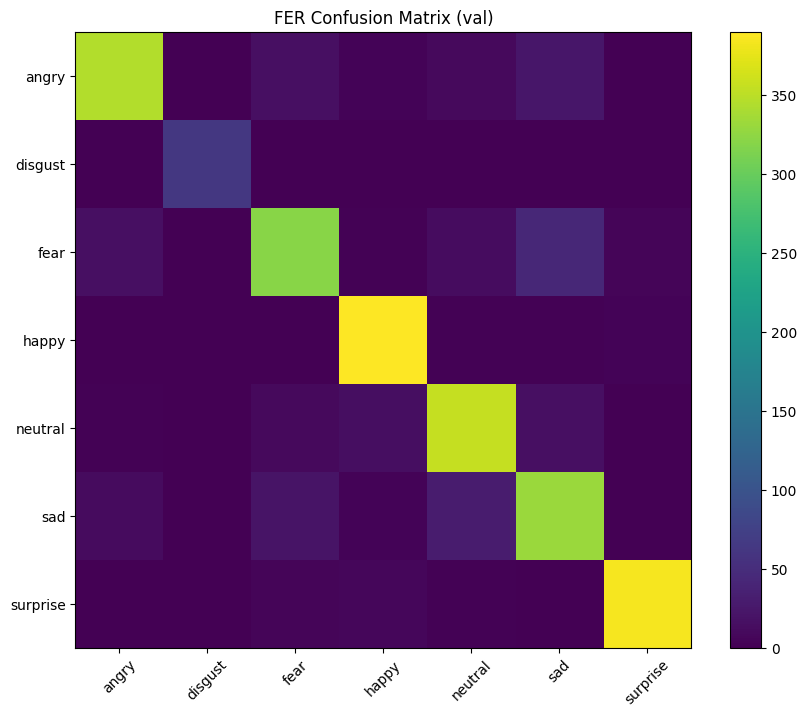

In [ ]:
import cv2
import numpy as np
from pathlib import Path
from ultralytics import YOLO
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

FER_WEIGHTS = r"runs/classify/fer_yolo_cls\weights\best.pt"
emo_model = YOLO(FER_WEIGHTS)

CLASSES = ["angry","disgust","fear","happy","neutral","sad","surprise"]
VAL_DIR = Path(r"data/fer2013\val")
IMG_EXT = {".jpg",".jpeg",".png",".bmp",".webp"}

y_true, y_pred = [], []
MAX_PER_CLASS = 400  # bump later if you want full eval

for cls in CLASSES:
    folder = VAL_DIR / cls
    imgs = [p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXT] if folder.exists() else []
    imgs = imgs[:MAX_PER_CLASS]

    for p in imgs:
        img = cv2.imread(str(p))
        if img is None:
            continue
        r = emo_model.predict(img, imgsz=224, verbose=False)[0]
        probs = r.probs.data.cpu().numpy()
        pred = CLASSES[int(probs.argmax())]
        y_true.append(cls)
        y_pred.append(pred)

print("Samples evaluated:", len(y_true))
print(classification_report(y_true, y_pred, labels=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
plt.figure(figsize=(10,8))
plt.imshow(cm)
plt.title("FER Confusion Matrix (val)")
plt.xticks(range(len(CLASSES)), CLASSES, rotation=45)
plt.yticks(range(len(CLASSES)), CLASSES)
plt.colorbar()
plt.show()


In [ ]:
import cv2, numpy as np
from ultralytics import YOLO
from collections import deque
from IPython.display import clear_output
import matplotlib.pyplot as plt

DET_WEIGHTS = r"runs/detect/face_detector\weights\best.pt"
FER_WEIGHTS = r"runs/classify/fer_yolo_cls\weights\best.pt"

det_model = YOLO(DET_WEIGHTS)
emo_model = YOLO(FER_WEIGHTS)

CLASSES = ["angry","disgust","fear","happy","neutral","sad","surprise"]

def clamp(v, lo, hi): return max(lo, min(hi, v))

def crop_face(frame, xyxy, pad=0.22):
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = map(int, xyxy)
    bw, bh = (x2-x1), (y2-y1)
    if bw <= 0 or bh <= 0:
        return None

    px, py = int(bw*pad), int(bh*pad)
    x1 = clamp(x1-px, 0, w-1); y1 = clamp(y1-py, 0, h-1)
    x2 = clamp(x2+px, 0, w-1); y2 = clamp(y2+py, 0, h-1)

    # force square crop
    bw, bh = (x2-x1), (y2-y1)
    side = max(bw, bh)
    cx, cy = (x1+x2)//2, (y1+y2)//2
    x1 = clamp(cx-side//2, 0, w-1); y1 = clamp(cy-side//2, 0, h-1)
    x2 = clamp(cx+side//2, 0, w-1); y2 = clamp(cy+side//2, 0, h-1)

    crop = frame[y1:y2, x1:x2]
    return crop if crop.size else None

class SmoothProbs:
    def __init__(self, n=15):
        self.q = deque(maxlen=n)
    def push(self, p):
        self.q.append(p)
        return np.mean(np.stack(self.q), axis=0)

def emo_probs(face):
    r = emo_model.predict(face, imgsz=224, verbose=False)[0]
    return r.probs.data.cpu().numpy()

cap = cv2.VideoCapture(0)
assert cap.isOpened(), "Camera not opened"

CONF_FACE = 0.35
IOU_FACE  = 0.5

MIN_EMO_CONF = 0.55  # raise to reduce fake neutral
smooth = SmoothProbs(n=15)

for _ in range(300):
    ret, frame = cap.read()
    if not ret:
        break

    det = det_model.predict(frame, conf=CONF_FACE, iou=IOU_FACE, device=0, verbose=False)[0]

    if det.boxes is not None and len(det.boxes) > 0:
        boxes = det.boxes.xyxy.cpu().numpy()
        areas = (boxes[:,2]-boxes[:,0])*(boxes[:,3]-boxes[:,1])
        box = boxes[int(np.argmax(areas))]  # biggest face only

        face = crop_face(frame, box)
        if face is not None:
            p = emo_probs(face)
            ps = smooth.push(p)

            idx = int(ps.argmax())
            conf = float(ps[idx])
            label = CLASSES[idx] if conf >= MIN_EMO_CONF else "unknown"

            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 2)
            cv2.putText(frame, f"{label} ({conf:.2f})", (x1, y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    clear_output(wait=True)
    plt.figure(figsize=(10,6))
    plt.imshow(rgb)
    plt.axis("off")
    plt.show()

cap.release()
print("Done.")


In [ ]:
import cv2, numpy as np
from ultralytics import YOLO
from collections import deque
from IPython.display import clear_output
import matplotlib.pyplot as plt

DET_WEIGHTS = r"runs/detect/face_detector\weights\best.pt"
FER_WEIGHTS = r"runs/classify/fer_yolo_cls\weights\best.pt"

det_model = YOLO(DET_WEIGHTS)
emo_model = YOLO(FER_WEIGHTS)

CLASSES = ["angry","disgust","fear","happy","neutral","sad","surprise"]

def clamp(v, lo, hi): return max(lo, min(hi, v))

def crop_face(frame, xyxy, pad=0.25):
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = map(int, xyxy)
    bw, bh = (x2-x1), (y2-y1)
    if bw <= 0 or bh <= 0:
        return None

    px, py = int(bw*pad), int(bh*pad)
    x1 = clamp(x1-px, 0, w-1); y1 = clamp(y1-py, 0, h-1)
    x2 = clamp(x2+px, 0, w-1); y2 = clamp(y2+py, 0, h-1)

    crop = frame[y1:y2, x1:x2]
    return crop if crop.size else None

class SmoothProbs:
    def __init__(self, n=10):
        self.q = deque(maxlen=n)
    def push(self, p):
        self.q.append(p)
        return np.mean(np.stack(self.q), axis=0)

smooth = SmoothProbs(n=10)

cap = cv2.VideoCapture(0)
assert cap.isOpened(), "Camera not opened"

CONF_FACE = 0.35
IOU_FACE  = 0.5

for t in range(200):
    ret, frame = cap.read()
    if not ret:
        break

    det = det_model.predict(frame, conf=CONF_FACE, iou=IOU_FACE, device=0, verbose=False)[0]

    clear_output(wait=True)

    if det.boxes is None or len(det.boxes) == 0:
        print("No face detected")
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10,6)); plt.imshow(rgb); plt.axis("off"); plt.show()
        continue

    boxes = det.boxes.xyxy.cpu().numpy()
    areas = (boxes[:,2]-boxes[:,0])*(boxes[:,3]-boxes[:,1])
    box = boxes[int(np.argmax(areas))]  # biggest face only

    face = crop_face(frame, box)
    if face is None:
        print("Face crop failed")
        continue

    r = emo_model.predict(face, imgsz=224, verbose=False)[0]
    p = r.probs.data.cpu().numpy()
    ps = smooth.push(p)

    idx = int(ps.argmax())
    conf = float(ps[idx])

    top3 = ps.argsort()[-3:][::-1]
    print(f"Pred: {CLASSES[idx]}  conf={conf:.3f}")
    print("Top-3:", [(CLASSES[i], float(ps[i])) for i in top3])

    # show frame + probs
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 2)
    cv2.putText(frame, f"{CLASSES[idx]} {conf:.2f}", (x1, y1-10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10,6))
    plt.imshow(rgb); plt.axis("off")
    plt.show()

    plt.figure(figsize=(10,3))
    plt.bar(CLASSES, ps)
    plt.ylim(0, 1)
    plt.xticks(rotation=30)
    plt.title("Emotion probabilities (smoothed)")
    plt.show()

cap.release()
print("Done.")


Pred: neutral  conf=0.676
Top-3: [('neutral', 0.6759740114212036), ('sad', 0.235831618309021), ('happy', 0.07104237377643585)]


In [ ]:
import cv2
import numpy as np
from ultralytics import YOLO
from collections import deque
import time

from IPython.display import display
import ipywidgets as widgets


DET_WEIGHTS = r"runs/detect/face_detector\weights\best.pt"
FER_WEIGHTS = r"runs/classify/fer_yolo_cls\weights\best.pt"

det_model = YOLO(DET_WEIGHTS)
emo_model = YOLO(FER_WEIGHTS)

CLASSES = ["angry","disgust","fear","happy","neutral","sad","surprise"]


HAS_DEEPFACE = False
try:
    from deepface import DeepFace
    HAS_DEEPFACE = True
except Exception:
    HAS_DEEPFACE = False


def clamp(v, lo, hi):
    return max(lo, min(hi, v))

def crop_face(frame, xyxy, pad=0.35):
    """
    Returns (crop_bgr, (x1,y1,x2,y2)) with padding.
    Increased default pad a bit to help age/gender stability.
    """
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = map(int, xyxy)
    bw, bh = (x2 - x1), (y2 - y1)
    if bw <= 0 or bh <= 0:
        return None, None

    px, py = int(bw * pad), int(bh * pad)
    x1 = clamp(x1 - px, 0, w - 1); y1 = clamp(y1 - py, 0, h - 1)
    x2 = clamp(x2 + px, 0, w - 1); y2 = clamp(y2 + py, 0, h - 1)

    crop = frame[y1:y2, x1:x2]
    if crop.size == 0:
        return None, None
    return crop, (x1, y1, x2, y2)

class SmoothProbs:
    def __init__(self, n=12):
        self.q = deque(maxlen=n)

    def push(self, p):
        self.q.append(p)
        return np.mean(np.stack(self.q), axis=0)

emo_smooth = SmoothProbs(n=12)


age_smooth = deque(maxlen=10)


gender_prob_smooth = deque(maxlen=12)  

def smooth_gender_probs(p_male, p_female):
    gender_prob_smooth.append([p_male, p_female])
    return np.mean(np.array(gender_prob_smooth), axis=0)

def gender_from_probs(pm, pf, margin=0.12):
    """
    margin: if male/female are too close -> 'unknown'
    """
    if pm is None or pf is None:
        return "N/A"
    if abs(pm - pf) < margin:
        return "unknown"
    return "male" if pm > pf else "female"

def draw_label(img, x, y, text, scale=0.6, thickness=2):
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thickness)
    H, W = img.shape[:2]
    x = clamp(x, 0, W - 1)
    y = clamp(y, th + 10, H - 1)

    cv2.rectangle(img, (x, y - th - 8), (x + tw + 10, y + 6), (0, 0, 0), -1)
    cv2.putText(img, text, (x + 5, y - 5),
                cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), thickness, cv2.LINE_AA)

def draw_bar(img, x, y, w, h, p, label):
    cv2.rectangle(img, (x, y), (x + w, y + h), (30, 30, 30), -1)
    fw = int(w * float(p))
    cv2.rectangle(img, (x, y), (x + fw, y + h), (0, 255, 0), -1)
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 255, 255), 1)
    draw_label(img, x + w + 8, y + h, f"{label}: {p:.2f}", scale=0.5, thickness=1)

def get_age_gender_probs(face_bgr):

    if not HAS_DEEPFACE:
        return None, (None, None)

    face_rgb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB)

    try:
        res = DeepFace.analyze(
            img_path=face_rgb,
            actions=["age", "gender"],
            enforce_detection=False,
            detector_backend="opencv"  
        )
        if isinstance(res, list):
            res = res[0]

        age = int(res.get("age")) if "age" in res else None

        pm = pf = None
        g = res.get("gender", None)

        
        if isinstance(g, dict):
            keys = {str(k).lower(): float(v) for k, v in g.items()}
            pf = keys.get("woman", keys.get("female", None))
            pm = keys.get("man", keys.get("male", None))

            if pf is not None and pm is not None:
                # convert % -> prob if needed
                if pf > 1.0 or pm > 1.0:
                    pf /= 100.0
                    pm /= 100.0
                # normalize
                s = pf + pm
                if s > 0:
                    pf /= s
                    pm /= s

        return age, (pm, pf)

    except Exception:
        return None, (None, None)


img_widget = widgets.Image(format="jpeg")
display(img_widget)
cap = cv2.VideoCapture(0)
assert cap.isOpened(), "Camera not opened"

CONF_FACE = 0.35
IOU_FACE  = 0.5


AGEGENDER_EVERY = 12


GENDER_RESET_EVERY = 100

frame_idx = 0
last_time = time.time()
fps_smooth = deque(maxlen=15)

print("Running... interrupt the cell to stop.")

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        det = det_model.predict(frame, conf=CONF_FACE, iou=IOU_FACE, device=0, verbose=False)[0]

        # defaults
        emo_label, emo_conf = "none", 0.0
        age_txt = "N/A"
        gender_txt = "N/A"
        pm_dbg = pf_dbg = None

        if det.boxes is not None and len(det.boxes) > 0:
            boxes = det.boxes.xyxy.cpu().numpy()
            areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
            box = boxes[int(np.argmax(areas))]  # biggest face only

            face, (x1, y1, x2, y2) = crop_face(frame, box, pad=0.35)
            if face is not None:
                # Emotion (YOLO classify)
                r = emo_model.predict(face, imgsz=224, verbose=False)[0]
                p = r.probs.data.cpu().numpy()
                ps = emo_smooth.push(p)

                idx = int(ps.argmax())
                emo_label = CLASSES[idx]
                emo_conf = float(ps[idx])

                # Age/Gender 
                if HAS_DEEPFACE and (frame_idx % AGEGENDER_EVERY == 0):
                    age, (pm, pf) = get_age_gender_probs(face)

                    if age is not None:
                        age_smooth.append(age)

                    if pm is not None and pf is not None:
                        sm_pm, sm_pf = smooth_gender_probs(pm, pf)
                        pm_dbg, pf_dbg = sm_pm, sm_pf

                # Prevent gender being "locked" forever
                if frame_idx % GENDER_RESET_EVERY == 0 and frame_idx > 0:
                    gender_prob_smooth.clear()

                # stabilized text
                if len(age_smooth) > 0:
                    age_txt = str(int(np.median(age_smooth)))

                if len(gender_prob_smooth) > 0:
                    sm_pm, sm_pf = np.mean(np.array(gender_prob_smooth), axis=0)
                    gender_txt = gender_from_probs(sm_pm, sm_pf, margin=0.12)
                    pm_dbg, pf_dbg = sm_pm, sm_pf

                # Draw bbox
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

                # Labels on same frame
                draw_label(frame, x1, y1,    f"Emotion: {emo_label} ({emo_conf:.2f})", scale=0.6)
                draw_label(frame, x1, y1+28, f"Gender: {gender_txt}", scale=0.6)
                draw_label(frame, x1, y1+56, f"Age: {age_txt}", scale=0.6)

                # Debug gender probs (helps you see if model is biased or uncertain)
                if pm_dbg is not None and pf_dbg is not None:
                    draw_label(frame, x1, y1+84, f"GProbs M:{pm_dbg:.2f} F:{pf_dbg:.2f}", scale=0.55, thickness=1)

                # Optional top3 emotion bars
                top3 = ps.argsort()[-3:][::-1]
                bx, by = 10, 10
                for k, i in enumerate(top3):
                    draw_bar(frame, bx, by + k * 22, 160, 14, ps[i], CLASSES[i])

        # FPS
        now = time.time()
        dt = now - last_time
        last_time = now
        if dt > 0:
            fps_smooth.append(1.0 / dt)
        fps = float(np.mean(fps_smooth)) if fps_smooth else 0.0
        draw_label(frame, 10, frame.shape[0] - 10, f"FPS: {fps:.1f}", scale=0.7)

        # Update widget (BGR -> RGB -> JPEG)
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ok, jpg = cv2.imencode(".jpg", rgb, [int(cv2.IMWRITE_JPEG_QUALITY), 85])
        if ok:
            img_widget.value = jpg.tobytes()

        frame_idx += 1

except KeyboardInterrupt:
    print("Stopped by user.")

cap.release()
print("Done.")


Image(value=b'', format='jpeg')

Running... interrupt the cell to stop.


Action: gender: 100%|██████████| 2/2 [00:00<00:00,  4.26it/s]


Stopped by user.
Done.


In [ ]:
import cv2
import numpy as np
from ultralytics import YOLO
from collections import deque
import time
import threading

from IPython.display import display
import ipywidgets as widgets

# -----------------------
# (A) MODELS PATHS
# -----------------------
DET_WEIGHTS = r"runs/detect/face_detector\weights\best.pt"
FER_WEIGHTS = r"runs/classify/fer_yolo_cls\weights\best.pt"

det_model = YOLO(DET_WEIGHTS)    # face detector
emo_model = YOLO(FER_WEIGHTS)    # FER classifier (7 emotions)

FACE_CLASSES = ["angry","disgust","fear","happy","neutral","sad","surprise"]

# -----------------------
# (B) Optional Age/Gender backend (DeepFace)
# -----------------------
HAS_DEEPFACE = False
try:
    from deepface import DeepFace
    HAS_DEEPFACE = True
except Exception:
    HAS_DEEPFACE = False

# -----------------------
# (C) Voice Emotion (Realtime)
# -----------------------
VOICE_ENABLED = True  # set False if you want to disable voice part quickly

HAS_VOICE = False
voice_label = "N/A"
voice_conf = 0.0
voice_lock = threading.Lock()

if VOICE_ENABLED:
    try:
        import sounddevice as sd
        from transformers import pipeline
        HAS_VOICE = True
    except Exception as e:
        HAS_VOICE = False
        print("Voice deps missing. Install with: pip install sounddevice transformers")
        print("Error:", e)

# We'll use SUPERB emotion model (4 classes)
VOICE_MODEL_NAME = "superb/hubert-large-superb-er"
VOICE_SR = 16000
VOICE_WINDOW_SEC = 2     # analyze last 2 seconds
VOICE_HOP_SEC = 0.25       # update every 0.75 sec
VOICE_SMOOTH_N = 6         # stabilize label

voice_label_hist = deque(maxlen=VOICE_SMOOTH_N)

def stable_majority_label(labels):
    if not labels:
        return None
    vals, counts = np.unique(labels, return_counts=True)
    return vals[int(np.argmax(counts))]

audio_buffer = deque(maxlen=int(VOICE_SR * VOICE_WINDOW_SEC))  # ring buffer of samples
audio_buffer_lock = threading.Lock()

def audio_callback(indata, frames, time_info, status):
    # indata shape: (frames, channels)
    if status:
        pass
    mono = indata[:, 0].copy()
    with audio_buffer_lock:
        audio_buffer.extend(mono.tolist())

def voice_thread_fn():
    global voice_label, voice_conf
    # model on CPU (so it doesn't steal GPU from YOLO)
    ser = pipeline("audio-classification", model=VOICE_MODEL_NAME, device=-1)

    # start mic stream
    with sd.InputStream(samplerate=VOICE_SR, channels=1, callback=audio_callback, dtype="float32"):
        last_run = 0.0
        while True:
            now = time.time()
            if now - last_run < VOICE_HOP_SEC:
                time.sleep(0.05)
                continue
            last_run = now

            # get last window
            with audio_buffer_lock:
                if len(audio_buffer) < int(VOICE_SR * 0.8):  # wait until we have enough
                    continue
                x = np.array(audio_buffer, dtype=np.float32)

            # normalize a bit (helps stability)
            mx = np.max(np.abs(x)) + 1e-9
            x = x / mx

            try:
                out = ser(x, sampling_rate=VOICE_SR, top_k=4)
                # out is list of dicts: [{'label': 'neutral', 'score': 0.7}, ...]
                best = out[0]
                lab = str(best["label"]).lower()
                conf = float(best["score"])

                voice_label_hist.append(lab)
                lab_stable = stable_majority_label(list(voice_label_hist)) or lab

                with voice_lock:
                    voice_label = lab_stable
                    voice_conf = conf
            except Exception:
                continue

voice_thread = None
if HAS_VOICE and VOICE_ENABLED:
    voice_thread = threading.Thread(target=voice_thread_fn, daemon=True)
    voice_thread.start()
    print("✅ Voice emotion thread started (mic realtime).")

# -----------------------
# (D) Helpers
# -----------------------
def clamp(v, lo, hi):
    return max(lo, min(hi, v))

def crop_face(frame, xyxy, pad=0.30):
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = map(int, xyxy)
    bw, bh = (x2-x1), (y2-y1)
    if bw <= 0 or bh <= 0:
        return None, None

    px, py = int(bw*pad), int(bh*pad)
    x1 = clamp(x1-px, 0, w-1); y1 = clamp(y1-py, 0, h-1)
    x2 = clamp(x2+px, 0, w-1); y2 = clamp(y2+py, 0, h-1)

    crop = frame[y1:y2, x1:x2]
    if crop.size == 0:
        return None, None
    return crop, (x1, y1, x2, y2)

class SmoothProbs:
    def __init__(self, n=10):
        self.q = deque(maxlen=n)
    def push(self, p):
        self.q.append(p)
        return np.mean(np.stack(self.q), axis=0)

emo_smooth = SmoothProbs(n=12)

age_smooth = deque(maxlen=9)
gender_smooth = deque(maxlen=9)



def draw_label(img, x, y, text, scale=0.6, thickness=2):
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thickness)
    cv2.rectangle(img, (x, y-th-8), (x+tw+10, y+6), (0,0,0), -1)
    cv2.putText(img, text, (x+5, y-5), cv2.FONT_HERSHEY_SIMPLEX, scale, (255,255,255), thickness)

def draw_bar(img, x, y, w, h, p, label):
    cv2.rectangle(img, (x, y), (x+w, y+h), (30,30,30), -1)
    fw = int(w * float(p))
    cv2.rectangle(img, (x, y), (x+fw, y+h), (0,255,0), -1)
    cv2.rectangle(img, (x, y), (x+w, y+h), (255,255,255), 1)
    draw_label(img, x+w+8, y+h, f"{label}: {p:.2f}", scale=0.5, thickness=1)


# -----------------------
# (E) Notebook live display widget (NO FLICKER)
# -----------------------
img_widget = widgets.Image(format="jpeg")
display(img_widget)

# -----------------------
# (F) Webcam loop
# -----------------------
cap = cv2.VideoCapture(0)
assert cap.isOpened(), "Camera not opened"

CONF_FACE = 0.35
IOU_FACE  = 0.5

AGEGENDER_EVERY = 12  # run DeepFace less frequently
frame_idx = 0

last_time = time.time()
fps_smooth = deque(maxlen=15)

print("Running... interrupt the cell to stop.")

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # -------------------
        # 1) Detect faces
        # -------------------
        det = det_model.predict(frame, conf=CONF_FACE, iou=IOU_FACE, device=0, verbose=False)[0]

        # default labels
        face_emo_label, face_emo_conf = "none", 0.0
        

        # -------------------
        # 2) Voice emotion
        # -------------------
        vlab, vconf = "N/A", 0.0
        if HAS_VOICE and VOICE_ENABLED:
            with voice_lock:
                vlab, vconf = voice_label, voice_conf

        # -------------------
        # 3) If face exists, classify emotion 
        # -------------------
        if det.boxes is not None and len(det.boxes) > 0:
            boxes = det.boxes.xyxy.cpu().numpy()
            areas = (boxes[:,2]-boxes[:,0])*(boxes[:,3]-boxes[:,1])
            box = boxes[int(np.argmax(areas))]  # biggest face only

            face, (x1,y1,x2,y2) = crop_face(frame, box, pad=0.30)
            if face is not None:
                # Face emotion
                r = emo_model.predict(face, imgsz=224, verbose=False)[0]
                p = r.probs.data.cpu().numpy()
                ps = emo_smooth.push(p)

                idx = int(ps.argmax())
                face_emo_label = FACE_CLASSES[idx]
                face_emo_conf = float(ps[idx])


                cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 2)

                draw_label(frame, x1, y1,     f"Face: {face_emo_label} ({face_emo_conf:.2f})", scale=0.6)


                # top3 face emotion bars
                top3 = ps.argsort()[-3:][::-1]
                bx, by = 10, 10
                for k, i in enumerate(top3):
                    draw_bar(frame, bx, by + k*22, 160, 14, ps[i], FACE_CLASSES[i])

        # -------------------
        # 4) Voice label overlay (always visible)
        # -------------------
        draw_label(frame, 10, frame.shape[0]-70, f"Voice: {vlab} ({vconf:.2f})", scale=0.7, thickness=2)

        # -------------------
        # 5) FPS
        # -------------------
        now = time.time()
        dt = now - last_time
        last_time = now
        if dt > 0:
            fps_smooth.append(1.0/dt)
        fps = float(np.mean(fps_smooth)) if fps_smooth else 0.0
        draw_label(frame, 10, frame.shape[0]-10, f"FPS: {fps:.1f}", scale=0.7)

        # -------------------
        # 6) Update widget (BGR -> JPEG)
        # -------------------
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ok, jpg = cv2.imencode(".jpg", rgb, [int(cv2.IMWRITE_JPEG_QUALITY), 85])
        if ok:
            img_widget.value = jpg.tobytes()

        frame_idx += 1

except KeyboardInterrupt:
    print("Stopped by user.")

cap.release()
print("Done.")



✅ Voice emotion thread started (mic realtime).


Image(value=b'', format='jpeg')

Running... interrupt the cell to stop.


Device set to use cpu


Stopped by user.
Done.
